In [1]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_iris

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (150, 4)
Target shape: (150,)


In [3]:
print(iris.feature_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [4]:
print(iris.target_names)

['setosa' 'versicolor' 'virginica']


In [5]:
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df["target"] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [6]:
# Select only Setosa (0) and Versicolor (1)

class_mask = (y == 0) | (y == 1)

X_binary = X[class_mask]
y_binary = y[class_mask]

print("X shape:", X_binary.shape)
print("y shape:", y_binary.shape)

X shape: (100, 4)
y shape: (100,)


In [7]:
# Select Petal Length and Petal Width

X_selected = X_binary[:, [2, 3]]

print("Selected feature shape:", X_selected.shape)

Selected feature shape: (100, 2)


In [8]:
print(X_selected[:5])
print(y_binary[:5])

[[1.4 0.2]
 [1.4 0.2]
 [1.3 0.2]
 [1.5 0.2]
 [1.4 0.2]]
[0 0 0 0 0]


In [9]:
df_binary = pd.DataFrame(
    X_selected,
    columns=["petal_length", "petal_width"]
)

df_binary["target"] = y_binary

df_binary.head()

,petal_length,petal_width,target
0,1.4,0.2,0
1,1.4,0.2,0
2,1.3,0.2,0
3,1.5,0.2,0
4,1.4,0.2,0


In [10]:
print(df_binary["target"].value_counts())

target
0    50
1    50
Name: count, dtype: int64


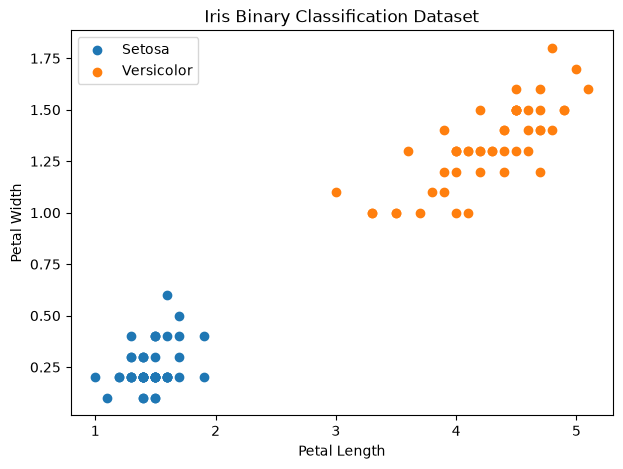

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    X_selected[y_binary == 0, 0],
    X_selected[y_binary == 0, 1],
    label="Setosa"
)

plt.scatter(
    X_selected[y_binary == 1, 0],
    X_selected[y_binary == 1, 1],
    label="Versicolor"
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Iris Binary Classification Dataset")
plt.legend()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X_selected,
    y_binary,
    test_size=0.20,
    random_state=42,
    stratify=y_binary
)

In [14]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(np.bincount(y_train))

print("\nTesting class distribution:")
print(np.bincount(y_test))

Training samples: 80
Testing samples: 20

Training class distribution:
[40 40]

Testing class distribution:
[10 10]


In [15]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaler.fit_transform(X_train)

scaler.transform(X_test)

array([[ 0.55      ,  0.52941176],
       [ 0.975     ,  0.94117647],
       [ 0.9       ,  0.76470588],
       [ 0.85      ,  0.82352941],
       [ 0.1       ,  0.05882353],
       [ 0.025     ,  0.05882353],
       [ 0.15      ,  0.05882353],
       [ 0.825     ,  0.76470588],
       [ 0.15      ,  0.11764706],
       [-0.025     ,  0.05882353],
       [ 0.05      ,  0.05882353],
       [ 0.875     ,  0.70588235],
       [ 0.075     ,  0.05882353],
       [ 0.05      ,  0.05882353],
       [ 0.1       ,  0.05882353],
       [ 0.55      ,  0.52941176],
       [ 0.7       ,  0.58823529],
       [ 0.075     ,  0.05882353],
       [ 0.9       ,  0.88235294],
       [ 0.85      ,  0.82352941]])

In [16]:
print("Original training data:")
print(X_train[:5])

print("\nScaled training data:")
print(X_train_scaled[:5])

Original training data:
[[1.5 0.4]
 [4.9 1.5]
 [3.5 1. ]
 [4.5 1.5]
 [4.5 1.5]]

Scaled training data:
[[0.1        0.17647059]
 [0.95       0.82352941]
 [0.6        0.52941176]
 [0.85       0.82352941]
 [0.85       0.82352941]]


In [17]:
print("Training minimum:", X_train_scaled.min(axis=0))
print("Training maximum:", X_train_scaled.max(axis=0))

Training minimum: [0. 0.]
Training maximum: [1. 1.]
